In [1]:
import pandas as pd
import numpy as np
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


df_kern = pd.read_csv('Data/data_kern_ALLratios_16_10.csv')
df_slag = pd.read_csv('Data/data_slag_ALLratios_16_10.csv')

In [2]:
# признаки - из baseline
features = [
    'Mo/Al', 'Si/Al', 'Cu', 'Sr/Ca', 'Si', 'Mo/(Mn+Mo)', '(Al+K+Ti)/S',
    'K/Al', 'P/Al', 'Ni', 'Ni/Fe', 'Ti/(Si+Ca+Mg)', 'Zr/Al',
    'dΔ_K/Al', 'rΔ_Mg', 'rΔ_(Al+K+Ti)/Si', 'dΔ_Ni', 'rΔ_(Ca+Mg)/Al',
    'Mn/Ca', 'Mo', '(10*Rb+Ti+10*Zr)/Se*1000', 'Fe/S', 'dΔ_Sr/Ca',
    'Ti/(Zr+Ti)', 'Ni/(Si+Ca+Mg)', 'Zn/Al', 'dΔ_Mo/Al', 'Fe/(Mn+Fe)',
    'rΔ_Mn', 'dΔ_Cu', '(Ca+Mg)/(Al+Si)', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_Si/Al',
    'Mg', '(Ti+Rb+Zr)/S', 'Zn', 'dΔ_Zn/Al', 'dΔ_Fe/S', 'dΔ_P/Al',
    'Sr', 'dΔ_(Al+K+Ti)/Si', 'rΔ_Zr/Si', 'Zr/Si', 'rΔ_S',
    'dΔ_(10*Rb+Ti+10*Zr)/Se*1000', 'rΔ_Mn/Ca', 'rΔ_Mo', 'rΔ_Mo/Al',
    'rΔ_Zn/Al', 'dΔ_Se/Si', 'dΔ_Al', 'dΔ_Ni/Al', 'rΔ_Cu', 'rΔ_Rb',
    'rΔ_Se/Si', 'rΔ_Ti/(Zr+Ti)', 'rΔ_S/(Rb+Zr)', 'dΔ_Fe/(Ca+Mg+Al)',
    '(Al+K+Ti)/Si', 'rΔ_P/Al', 'dΔ_S/(Rb+Zr)'
]

In [3]:
# гиперпараметры из baseline
params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'l2_leaf_reg': 3,
    'loss_function': 'MultiClass',
    'random_seed': 42,
    'verbose': 0,
    'task_type': 'GPU',
    'devices': '0'
}

In [4]:
X_train = df_kern[features]
y_train = df_kern['Strat']

X_test = df_slag[features]
y_test = df_slag['Stratigraphy']

print(f"train: {len(X_train)} проб, {len(features)} признаков")
print(f"test:  {len(X_test)} проб")

train: 3028 проб, 61 признаков
test:  8644 проб



F1 macro (raw): 0.4173

Classification Report:
              precision    recall  f1-score   support

           0     0.0000    0.0000    0.0000         0
           1     0.0000    0.0000    0.0000         0
           2     0.0000    0.0000    0.0000       226
           3     0.9424    0.8738    0.9068      4304
           4     0.7445    0.9331    0.8282      2123
           5     0.6260    0.3919    0.4820       393
           6     0.7571    0.2650    0.3926       200
           7     0.4148    0.2857    0.3384       196
           8     0.3776    0.8156    0.5162       244
           9     0.7267    0.9416    0.8203       257
          10     0.2672    0.5385    0.3571        65
          11     0.9536    0.2264    0.3659       636

    accuracy                         0.7664      8644
   macro avg     0.4842    0.4393    0.4173      8644
weighted avg     0.8119    0.7664    0.7622      8644



/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _wa

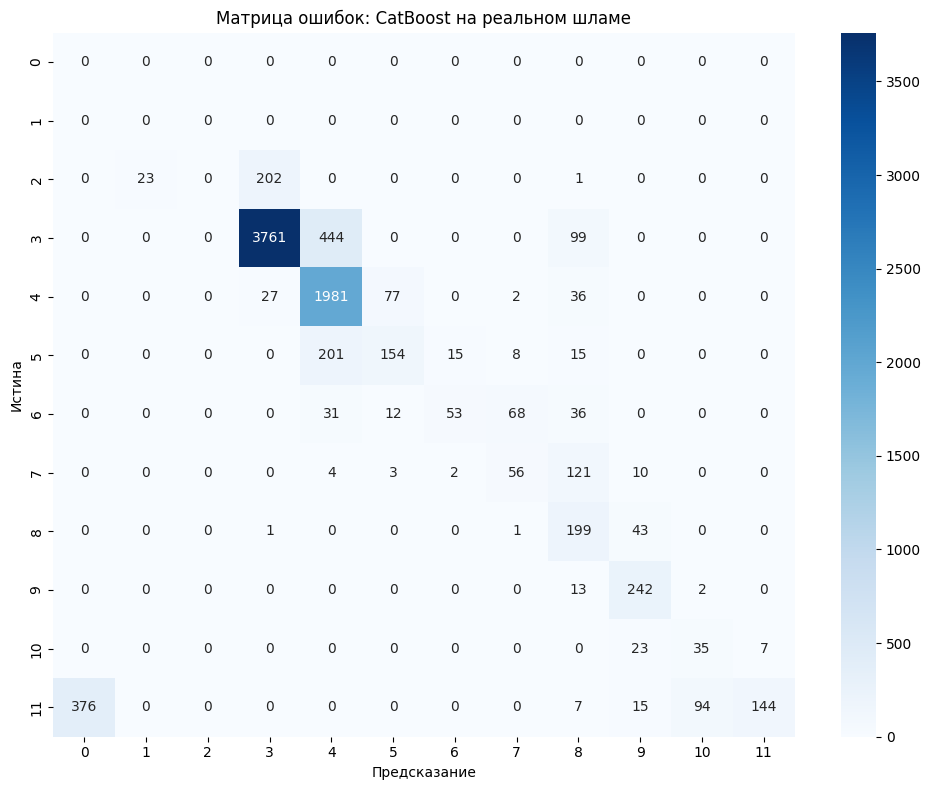

In [5]:
# обучение на керне
model = CatBoostClassifier(**params)
model.fit(X_train, y_train)

# тест на шламе
y_pred = model.predict(X_test)

f1_raw = f1_score(y_test, y_pred, average='macro')
print(f"\nF1 macro (raw): {f1_raw:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))

# ── 6. матрица ошибок ──
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Матрица ошибок: CatBoost на реальном шламе')
plt.tight_layout()
plt.show()

**Анализ классов**

In [6]:
# какие классы есть
kern_classes = sorted(df_kern['Strat'].dropna().unique())
slag_classes = sorted(df_slag['Stratigraphy'].dropna().unique())



print(f"классы в керне: {kern_classes}")
print(f"классы в шламе: {slag_classes}")

# классы только в шламе (модель их не видела)
only_slag = set(slag_classes) - set(kern_classes)
print(f"\nтолько в шламе (модель не видела): {sorted(only_slag)}")

# классы только в керне (в шламе нет)
only_kern = set(kern_classes) - set(slag_classes)
print(f"только в керне (в шламе нет): {sorted(only_kern)}")

# сколько проб каждого класса
print("\nпробы по классам:")
print("\nкерн:")
print(df_kern['Strat'].value_counts().sort_index())
print("\nшлам:")
print(df_slag['Stratigraphy'].value_counts().sort_index())

классы в керне: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
классы в шламе: [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

только в шламе (модель не видела): []
только в керне (в шламе нет): [0, 1]

пробы по классам:

керн:
Strat
0     448
1     156
2     182
3     267
4     233
5     133
6     131
7     194
8     365
9     469
10    267
11    183
Name: count, dtype: int64

шлам:
Stratigraphy
2      226
3     4304
4     2123
5      393
6      200
7      196
8      244
9      257
10      65
11     636
Name: count, dtype: int64


**Повтор эксперимента, без классов 0 и 1**


F1 macro (классы 2–11): 0.5008

Classification Report:
              precision    recall  f1-score   support

           2     0.0000    0.0000    0.0000       226
           3     0.9424    0.8738    0.9068      4304
           4     0.7445    0.9331    0.8282      2123
           5     0.6260    0.3919    0.4820       393
           6     0.7571    0.2650    0.3926       200
           7     0.4148    0.2857    0.3384       196
           8     0.3776    0.8156    0.5162       244
           9     0.7267    0.9416    0.8203       257
          10     0.2672    0.5385    0.3571        65
          11     0.9536    0.2264    0.3659       636

   micro avg     0.8035    0.7664    0.7845      8644
   macro avg     0.5810    0.5272    0.5008      8644
weighted avg     0.8119    0.7664    0.7622      8644



/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

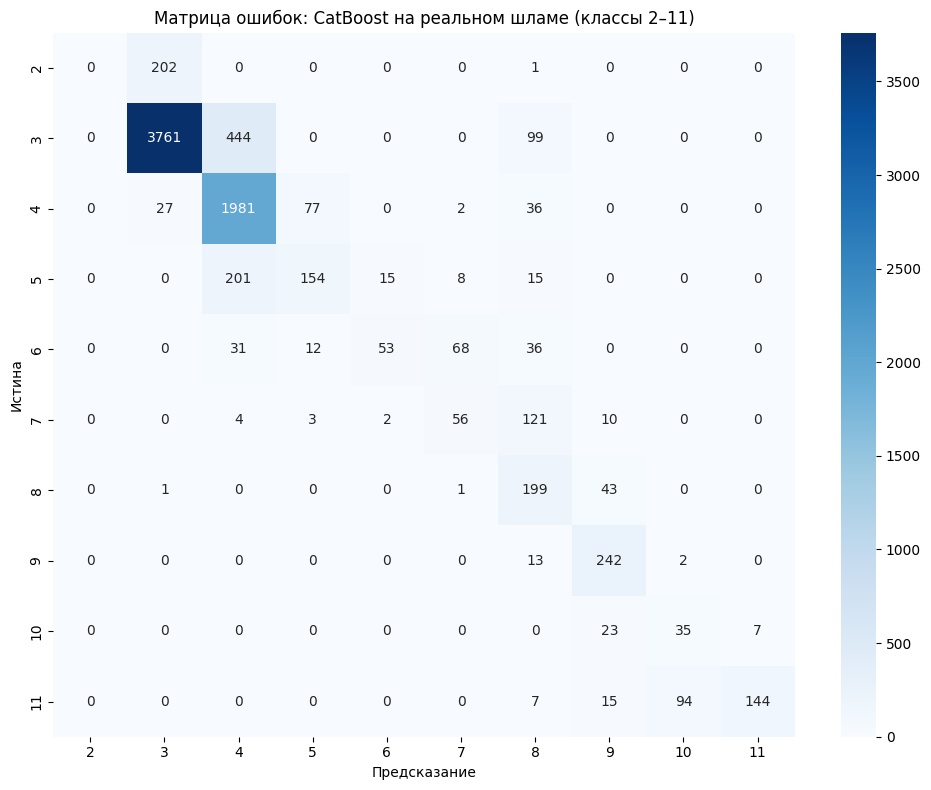

In [7]:
classes_to_keep = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

f1 = f1_score(y_test, y_pred, average='macro', labels=classes_to_keep)
print(f"\nF1 macro (классы 2–11): {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, labels=classes_to_keep, digits=4))

# матрица ошибок
plt.figure(figsize=(10, 8))
cm = confusion_matrix(y_test, y_pred, labels=classes_to_keep)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=classes_to_keep, yticklabels=classes_to_keep)
plt.xlabel('Предсказание')
plt.ylabel('Истина')
plt.title('Матрица ошибок: CatBoost на реальном шламе (классы 2–11)')
plt.tight_layout()
plt.show()

**Распределение классов**

In [8]:
classes_to_keep = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

kern_dist = df_kern[df_kern['Strat'].isin(classes_to_keep)]['Strat'].value_counts(normalize=True).sort_index() * 100
slag_dist = df_slag[df_slag['Stratigraphy'].isin(classes_to_keep)]['Stratigraphy'].value_counts(normalize=True).sort_index() * 100

comparison = pd.DataFrame({
    'керн, %': kern_dist,
    'шлам, %': slag_dist,
    'разница, п.п.': slag_dist - kern_dist
})
print(comparison.round(2))

    керн, %  шлам, %  разница, п.п.
0     14.80      NaN            NaN
1      5.15      NaN            NaN
2      6.01     2.61          -3.40
3      8.82    49.79          40.97
4      7.69    24.56          16.87
5      4.39     4.55           0.15
6      4.33     2.31          -2.01
7      6.41     2.27          -4.14
8     12.05     2.82          -9.23
9     15.49     2.97         -12.52
10     8.82     0.75          -8.07
11     6.04     7.36           1.31


**Оценка вклада viterbi на реальном шламе**

Керн: 3028 проб
Шлам: 8644 проб

Колонки шлама: ['Well', 'Sample', 'Depth', 'Stratigraphy', 'Mg', 'Al', 'Si', 'P', 'S', 'K', 'Ca', 'Ti', 'Mn', 'Fe', 'Ni', 'Cu', 'Zn', 'Se', 'Rb', 'Sr', 'Zr', 'Mo', '(Ca+Mg)/(Al+Si)', 'Sr/Ca', 'Mn/Ca', '(Al+K)/(Ca+Mg+Si)', 'Zr/Al', 'Zr/Si', 'K/Al', 'Ti/(Zr+Ti)', 'Si/Al', 'P/Al', 'Ni/Fe', 'Ni/(Si+Ca+Mg)', 'S/(Rb+Zr)', 'Mo/Al', 'Mo/(Mn+Mo)', 'Mn/Al', 'Fe/S', 'Ni/S', 'Fe/(Ca+Mg+Al)', 'Ti/(Si+Ca+Mg)', 'Fe/(Mn+Fe)', '(Al+K+Ti)/Si', '(Al+K+Ti)/S', '(Ti+Rb+Zr)/S', 'S/Ti', 'Ni/Al', 'Zn/Al', 'Se/Si', '(Ca+Mg)/Al', 'Se/Ti', '(10*Rb+Ti+10*Zr)/Se*1000', 'dΔ_Mg', 'dΔ_Al', 'dΔ_Si', 'dΔ_P', 'dΔ_S', 'dΔ_K', 'dΔ_Ca', 'dΔ_Ti', 'dΔ_Mn', 'dΔ_Fe', 'dΔ_Ni', 'dΔ_Cu', 'dΔ_Zn', 'dΔ_Se', 'dΔ_Rb', 'dΔ_Sr', 'dΔ_Zr', 'dΔ_Mo', 'dΔ_(Ca+Mg)/(Al+Si)', 'dΔ_Sr/Ca', 'dΔ_Mn/Ca', 'dΔ_(Al+K)/(Ca+Mg+Si)', 'dΔ_Zr/Al', 'dΔ_Zr/Si', 'dΔ_K/Al', 'dΔ_Ti/(Zr+Ti)', 'dΔ_Si/Al', 'dΔ_P/Al', 'dΔ_Ni/Fe', 'dΔ_Ni/(Si+Ca+Mg)', 'dΔ_S/(Rb+Zr)', 'dΔ_Mo/Al', 'dΔ_Mo/(Mn+Mo)', 'dΔ_Mn/Al', 'dΔ_Fe/S', 'dΔ_Ni/S', 'dΔ_F

/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/maria/.pyenv/versions/3.11.5/envs/mipt-work/lib/python3.11/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavio

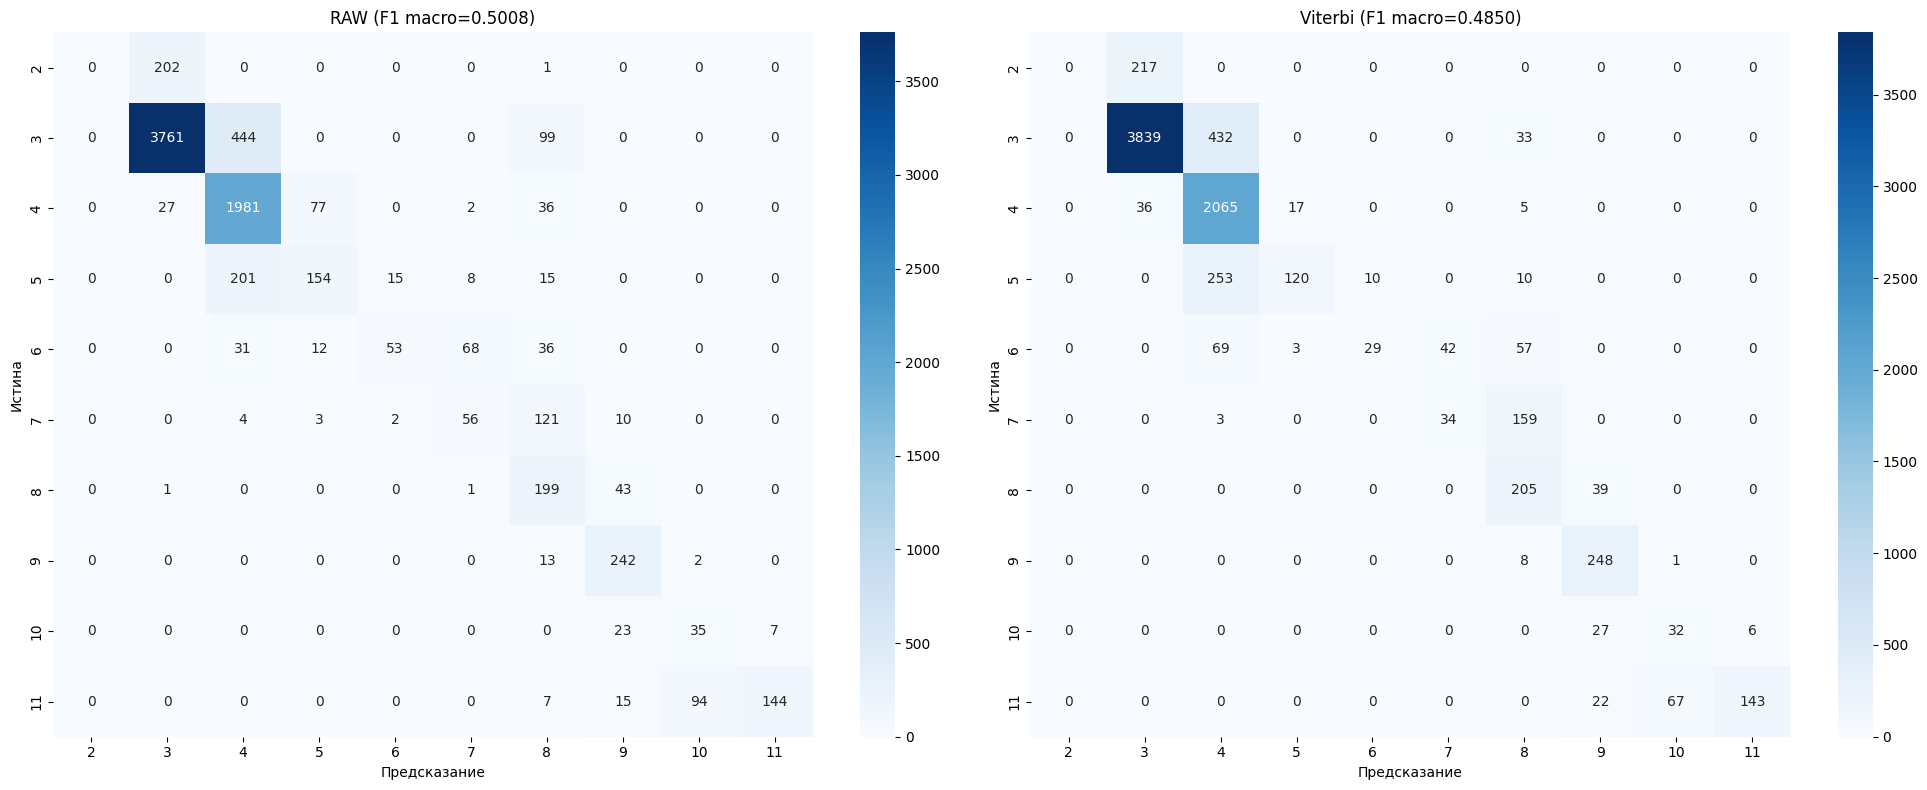


Per-class F1
 Класс        RAW    Viterbi    Δ, п.п.
----------------------------------------
     2     0.0000     0.0000     +0.00
     3     0.9068     0.9145     +0.77
     4     0.8282     0.8352     +0.70
     5     0.4820     0.4503     -3.17
     6     0.3926     0.2427    -14.99
     7     0.3384     0.2500     -8.84
     8     0.5162     0.5687     +5.24
     9     0.8203     0.8364     +1.61
    10     0.3571     0.3879     +3.07
    11     0.3659     0.3643     -0.16

Viterbi изменил 667 предсказаний из 8644 (7.72%)

Распределение предсказаний по классам
 Класс     RAW, %   Viterbi, %    Δ, п.п.
---------------------------------------------
     2       0.00         0.00     +0.00
     3      46.17        47.34     +1.17
     4      30.78        32.65     +1.86
     5       2.85         1.62     -1.23
     6       0.81         0.45     -0.36
     7       1.56         0.88     -0.68
     8       6.10         5.52     -0.58
     9       3.85         3.89     +0.03
    10    

In [9]:
# CatBoost на керне → предсказание на шламе → Viterbi

import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns


print(f"Керн: {len(df_kern)} проб")
print(f"Шлам: {len(df_slag)} проб")
print(f"\nКолонки шлама: {df_slag.columns.tolist()}")


X_kern = df_kern[features]
y_kern = df_kern['Strat']
wells_kern = df_kern['Well']         

X_slag = df_slag[features]
y_slag = df_slag['Stratigraphy']
wells_slag = df_slag['Well']         

print(f"\nКерн: {wells_kern.nunique()} скважин")
print(f"Шлам: {wells_slag.nunique()} скважин")

# Гиперпараметры из baseline (фиксированные) 
fixed_params = {
    'depth': 6,
    'iterations': 500,
    'learning_rate': 0.1,
    'l2_leaf_reg': 3,
    'loss_function': 'MultiClass',
    'random_seed': 42,
    'verbose': 0,
    'task_type': 'GPU',
    'devices': '0'
}

# Обучение CatBoost на ВСЁМ керне
print("\nОбучение CatBoost на всём керне")
model = CatBoostClassifier(**fixed_params)
model.fit(X_kern, y_kern)

classes = model.classes_
n_classes = len(classes)
print(f"Классы модели: {classes}")

# Функции для HMM 
def build_transition_matrix(y_train, wells_train, n_classes=12):
    """
    Матрица переходов P(класс_{t+1} | класс_t) по train-керну.
    Строится по последовательностям внутри каждой скважины.
    """
    trans = np.ones((n_classes, n_classes))  # Laplace smoothing
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        for i in range(len(labels) - 1):
            trans[labels[i], labels[i+1]] += 1
    trans = trans / trans.sum(axis=1, keepdims=True)
    return trans


def build_start_probs(y_train, wells_train, n_classes=12):
    """
    Начальные вероятности: какой класс чаще всего встречается первым в скважине.
    """
    start = np.ones(n_classes)  # Laplace
    for well in wells_train.unique():
        mask = wells_train == well
        labels = y_train[mask].values
        start[labels[0]] += 1
    return start / start.sum()


def viterbi_decode(probs_well, trans_mat, start_probs):
    """
    Viterbi-декодирование для одной скважины.
    probs_well: (n_samples, n_classes) — emission probabilities от CatBoost
    Возвращает наиболее правдоподобную последовательность классов.
    """
    n_samples, n_classes = probs_well.shape
    
    log_emission = np.log(probs_well + 1e-12)
    log_trans = np.log(trans_mat + 1e-12)
    log_start = np.log(start_probs + 1e-12)
    
    dp = np.full((n_samples, n_classes), -np.inf)
    backptr = np.zeros((n_samples, n_classes), dtype=int)
    
    # Инициализация
    dp[0] = log_start + log_emission[0]
    
    # Рекурсия
    for t in range(1, n_samples):
        for j in range(n_classes):
            candidates = dp[t-1] + log_trans[:, j]
            backptr[t, j] = np.argmax(candidates)
            dp[t, j] = candidates[backptr[t, j]] + log_emission[t, j]
    
    # Backtrack
    path = np.zeros(n_samples, dtype=int)
    path[-1] = np.argmax(dp[-1])
    for t in range(n_samples - 2, -1, -1):
        path[t] = backptr[t+1, path[t+1]]
    
    return path


# Построение HMM по КЕРНУ (train) 
trans_mat = build_transition_matrix(y_kern, wells_kern, n_classes=n_classes)
start_probs = build_start_probs(y_kern, wells_kern, n_classes=n_classes)

print("\nДиагональ матрицы переходов (P(class→class)):")
for i, c in enumerate(classes):
    print(f"  P({c} → {c}) = {trans_mat[i, i]:.4f}")

# Предсказания на ШЛАМЕ (разметка шлама НЕ используется) ──
print("\nПредсказание на шламе...")
y_pred_raw = model.predict(X_slag).ravel()
probs_slag = model.predict_proba(X_slag)

# Viterbi по каждой скважине ШЛАМА отдельно 
# Матрица переходов ОТ КЕРНА!
y_pred_viterbi = np.zeros(len(X_slag), dtype=int)

# Определяем колонку с глубиной (для сортировки)
depth_col = None
for cand in ['depth', 'Depth', 'DEPTH', 'Глубина', 'глубина']:
    if cand in df_slag.columns:
        depth_col = cand
        break

print(f"Колонка глубины: {depth_col}")
print(f"Viterbi применяется к {wells_slag.nunique()} скважинам шлама:")

for well in wells_slag.unique():
    well_mask = (wells_slag == well).values
    idx = np.where(well_mask)[0]
    
    if len(idx) == 0:
        continue
    
    # Сортировка по глубине внутри скважины
    if depth_col is not None:
        depths = df_slag.iloc[idx][depth_col].values
        order = np.argsort(depths)
        idx_sorted = idx[order]
    else:
        # Если нет depth — предполагаем, что данные уже в порядке бурения
        idx_sorted = idx
    
    probs_well = probs_slag[idx_sorted]
    path = viterbi_decode(probs_well, trans_mat, start_probs)
    
    # Записываем обратно
    y_pred_viterbi[idx_sorted] = path
    
    print(f"  {well}: {len(idx_sorted)} проб")

# Оценка метрик
classes_to_keep = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]

f1_raw = f1_score(y_slag, y_pred_raw, average='macro', labels=classes_to_keep)
f1_vit = f1_score(y_slag, y_pred_viterbi, average='macro', labels=classes_to_keep)

print(f"\n{'='*60}")
print(f"F1 macro (raw, классы 2–11):     {f1_raw:.4f}")
print(f"F1 macro (Viterbi, классы 2–11): {f1_vit:.4f}")
print(f"Вклад Viterbi:                   {(f1_vit - f1_raw) * 100:+.2f} п.п.")
print(f"{'='*60}")

# Classification Report
print("\nClassification Report: RAW")
print(classification_report(y_slag, y_pred_raw, labels=classes_to_keep, digits=4))

print("\nClassification Report: VITERBI")
print(classification_report(y_slag, y_pred_viterbi, labels=classes_to_keep, digits=4))

# Матрицы ошибок
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

for ax, (y_pred, title) in zip(axes, [
    (y_pred_raw, f'RAW (F1 macro={f1_raw:.4f})'),
    (y_pred_viterbi, f'Viterbi (F1 macro={f1_vit:.4f})')
]):
    cm = confusion_matrix(y_slag, y_pred, labels=classes_to_keep)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes_to_keep, yticklabels=classes_to_keep, ax=ax)
    ax.set_xlabel('Предсказание')
    ax.set_ylabel('Истина')
    ax.set_title(title)

plt.tight_layout()
plt.savefig('confusion_matrices_raw_vs_viterbi.png', dpi=150, bbox_inches='tight')
plt.show()

# Per-class F1: сравнение
f1_raw_per = f1_score(y_slag, y_pred_raw, average=None, labels=classes_to_keep)
f1_vit_per = f1_score(y_slag, y_pred_viterbi, average=None, labels=classes_to_keep)

print("\nPer-class F1")
print(f"{'Класс':>6} {'RAW':>10} {'Viterbi':>10} {'Δ, п.п.':>10}")
print("-" * 40)
for c, f_raw, f_vit in zip(classes_to_keep, f1_raw_per, f1_vit_per):
    print(f"{c:>6} {f_raw:>10.4f} {f_vit:>10.4f} {(f_vit-f_raw)*100:>+9.2f}")

# Анализ: сколько предсказаний изменил Viterbi
n_changed = (y_pred_raw != y_pred_viterbi).sum()
print(f"\nViterbi изменил {n_changed} предсказаний из {len(y_slag)} ({100*n_changed/len(y_slag):.2f}%)")

# Как Viterbi перераспределил предсказания по классам
print("\nРаспределение предсказаний по классам")
print(f"{'Класс':>6} {'RAW, %':>10} {'Viterbi, %':>12} {'Δ, п.п.':>10}")
print("-" * 45)
for c in classes_to_keep:
    raw_pct = 100 * (y_pred_raw == c).sum() / len(y_slag)
    vit_pct = 100 * (y_pred_viterbi == c).sum() / len(y_slag)
    print(f"{c:>6} {raw_pct:>10.2f} {vit_pct:>12.2f} {vit_pct-raw_pct:>+9.2f}")

**полная таблица переходов**

In [10]:
# Красивая таблица с 4 знаками после запятой
trans_df = pd.DataFrame(
    trans_mat,
    index=[f'из {c}' for c in classes],
    columns=[f'в {c}' for c in classes]
)
print("Матрица переходов P(класс_{t+1} | класс_t):")
print(trans_df.round(5).to_string())


Матрица переходов P(класс_{t+1} | класс_t):
           в 0      в 1      в 2      в 3      в 4      в 5      в 6      в 7      в 8      в 9     в 10     в 11
из 0   0.97550  0.00223  0.00223  0.00223  0.00223  0.00223  0.00223  0.00223  0.00223  0.00223  0.00223  0.00223
из 1   0.06587  0.87425  0.00599  0.00599  0.00599  0.00599  0.00599  0.00599  0.00599  0.00599  0.00599  0.00599
из 2   0.00518  0.06218  0.88601  0.00518  0.00518  0.00518  0.00518  0.00518  0.00518  0.00518  0.00518  0.00518
из 3   0.00358  0.00358  0.04659  0.91756  0.00358  0.00358  0.00358  0.00358  0.00358  0.00358  0.00358  0.00358
из 4   0.00408  0.00408  0.00408  0.05306  0.90204  0.00816  0.00408  0.00408  0.00408  0.00408  0.00408  0.00408
из 5   0.01379  0.00690  0.00690  0.00690  0.08966  0.83448  0.00690  0.00690  0.00690  0.00690  0.00690  0.00690
из 6   0.00699  0.00699  0.00699  0.00699  0.01399  0.09091  0.83217  0.00699  0.00699  0.00699  0.00699  0.00699
из 7   0.00485  0.00485  0.00485  0.00485  0

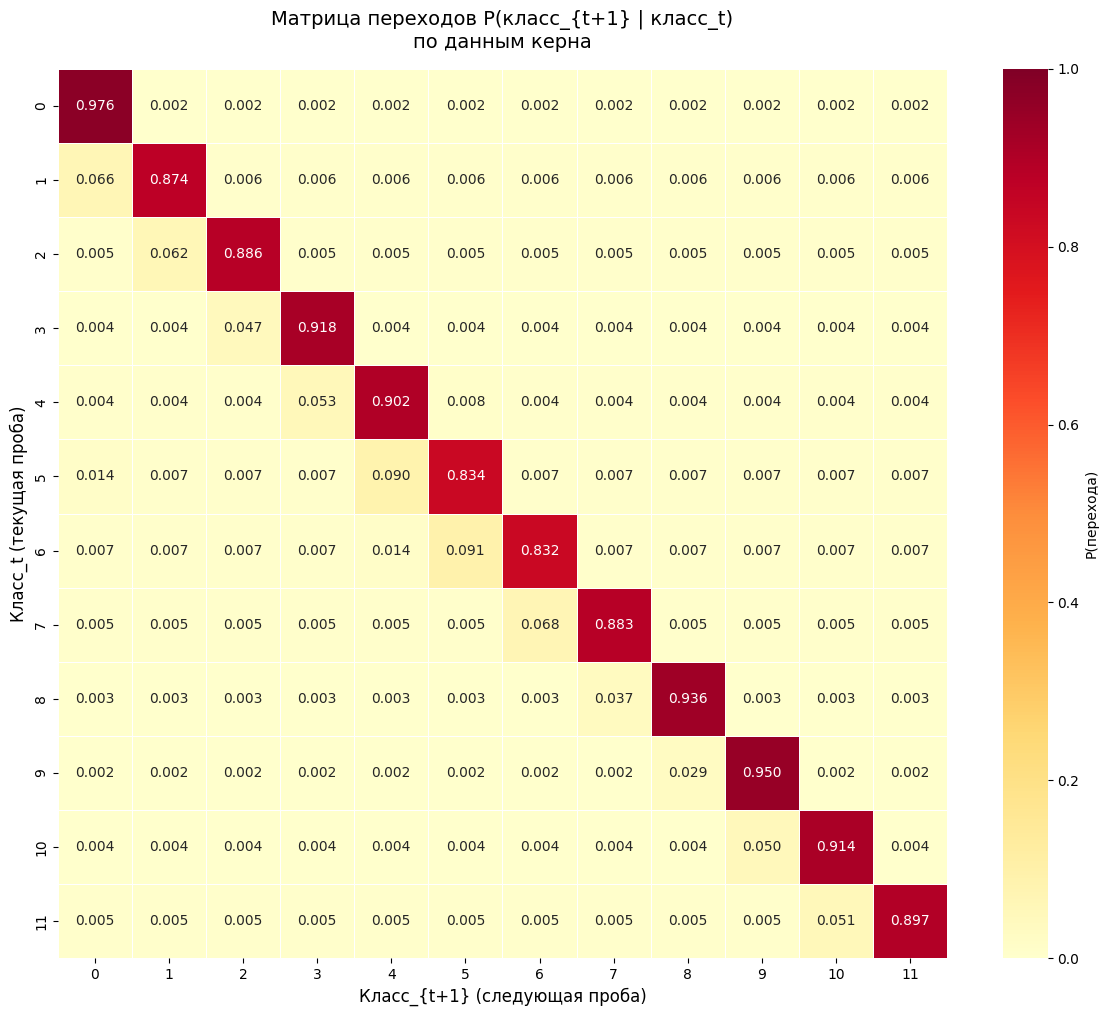

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Строим матрицу переходов (как в baseline)
trans_mat = build_transition_matrix(y_kern, wells_kern, n_classes=n_classes)

# Красивая визуализация матрицы переходов
fig, ax = plt.subplots(figsize=(12, 10))

sns.heatmap(
    trans_mat,
    annot=True,           
    fmt='.3f',            
    cmap='YlOrRd',        
    xticklabels=classes,  
    yticklabels=classes,  
    vmin=0, vmax=1,       
    cbar_kws={'label': 'P(перехода)'},
    ax=ax,
    square=True,
    linewidths=0.5,
    linecolor='white'
)

ax.set_xlabel('Класс_{t+1} (следующая проба)', fontsize=12)
ax.set_ylabel('Класс_t (текущая проба)', fontsize=12)
ax.set_title('Матрица переходов P(класс_{t+1} | класс_t)\nпо данным керна', fontsize=14, pad=15)

plt.tight_layout()
plt.savefig('transition_matrix_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

**Определение начального класса по керну и по шламу**

In [12]:
# Первые классы в керне (по скважинам)
first_kern = []
for well in wells_kern.unique():
    first_kern.append(y_kern[wells_kern == well].values[0])
print("Первые классы в керне:", pd.Series(first_kern).value_counts().sort_index())

# Первые классы в шламе (по скважинам, отсортированным по глубине)
first_slag = []
for well in wells_slag.unique():
    mask = wells_slag == well
    idx = df_slag[mask].index
    depths = df_slag.loc[idx, 'Depth'].values
    first_idx = idx[np.argmin(depths)]  # самая верхняя проба
    first_slag.append(df_slag.loc[first_idx, 'Stratigraphy'])
print("Первые классы в шламе:", pd.Series(first_slag).value_counts().sort_index())

Первые классы в керне: 8     1
10    4
11    9
Name: count, dtype: int64
Первые классы в шламе: 11    21
Name: count, dtype: int64
